# 1. 합성곱 신경망 (CNN, Convolutional NN)

### 픽셀
- 이미지 데이터를 구성하는 가장 기본적인 단위
- 색상 또는 밝기 정보 포함

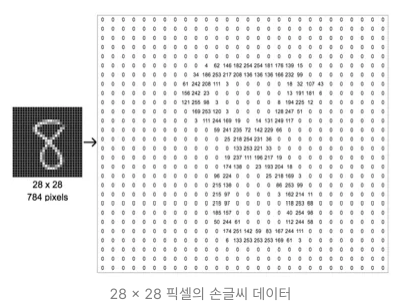

- 흑백(Grayscale) 이미: 밝기만
컬러 이미지: 색상 값으로 표현

### 채널
-  이미지의 색상 정보를 구성하는 각각의 데이터 층

### 색공간
- 예시) 그레이 스케일(Grayscale), RGB, HSV

### 텐서
- 텐서는 수학과 프로그래밍(특히 딥러닝)에서 다차원 데이터 배열(Multi-dimensional
Array)을 통칭하는 용어
- 스칼라, 벡터, 행렬 아우르는 개념
- 숫자 1개: 0차원 텐서
- 숫자 일렬로(벡터): 1차원 텐서
- 행렬(행과 열로 이루어진 2차원 표): 2차원 텐서
- 행렬 여러개 / 채널, 배치 등의 추가 축 포함된 다차원 구조: 3차원 이상 텐서

예시1) 28 * 28 * 1 = 흑백이미지텐서 (3차원이겟지?)
예시2) 28 * 28 * 3  = RGB 컬러 이미지 텐서

# CNN

- 컴퓨터는 픽셀 하나하나 살펴보면서 물체 인식
- 사람은 중요한 영역, 특징에 집중

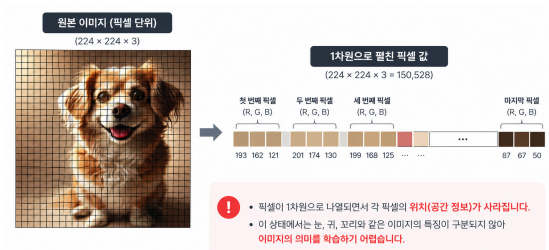

- 픽셀 정보를 그냥 학습하면 생기는 문제점
    - 단순히 1차원 배열로 펼쳐서 학습하면 원래 이미지가 가지고 있던 2차원 공간 구조가 명확하게 활용되지 X
    - 이미지의 특징을 학습하기 어렵


# MLP와 CNN의 구조 비교

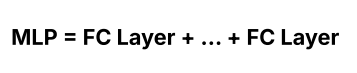


- MLP는 입력된 데이터를 FC Layer에 전달하여 학습하는 구조
- 2차원 이미지를 1차원 배열로 펼친 뒤 사용

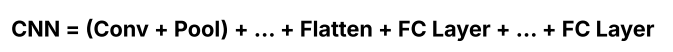

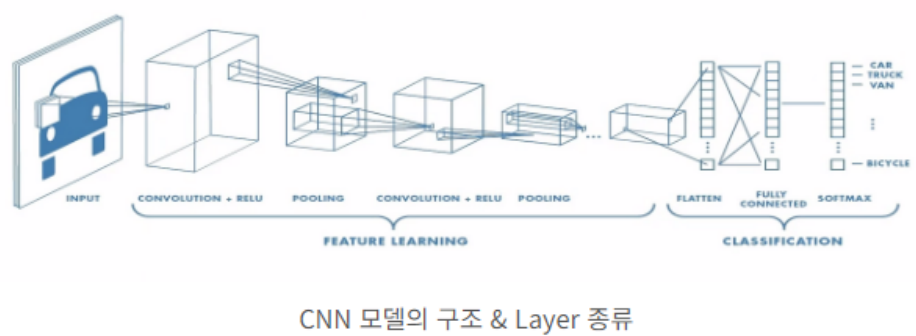

- CNN은 이미지의 공간적 특징을 유지하면서 Conv와 Pool을 반복하여 이미지의 특징
을 추출

- MLP와 CNN의 가장 큰 차이점은, CNN이 FC Layer를 적용하기 전 **Conv와Pool을 이용해 이미지의 특징을 학습하는 과정이 추가**된다는 점

특징 추출 (Feature Learning)

- Convolution Layer / 필터(Kernel)를 이미지 위에서 이동시키며 모서리, 질감, 형태 등 이미지의 다양한 특징을 추출
- Pooling Layer / 추출된 특징 맵의 크기를 줄이고 중요한 특징을 유지하여 연산량을 감소시킴

- Flatten / 여러 차원으로 이루어진 특징 맵을 FC Layer에 입력할 수 있도록 1차원 배열로 변환

- (Conv + Pool)을 반복하여 이미지의 공간적 특징을 추출한 후 FC Layer를 통해 분류
한다는 점이 CNN의 핵심 구조

### 흑백 이미지 vs 컬러 이미지
- 흑백이미지는 H * W 의 2차원으로 표현 가능
- 컬러는 여기에 R, G, B 중 골라야 해서 *3 해서 3차원

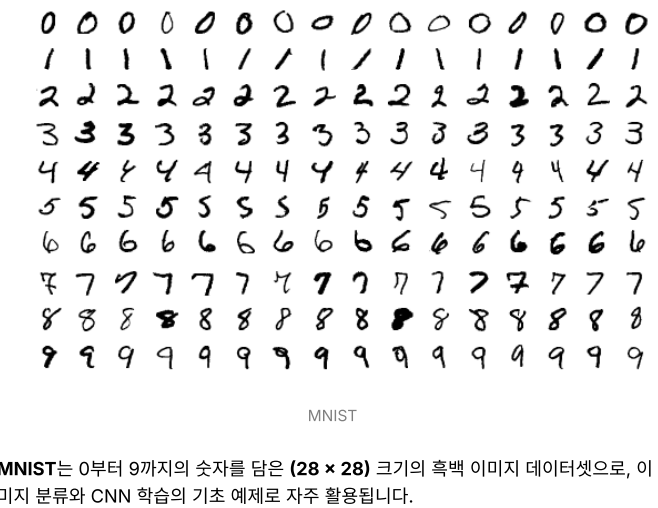

대표적인 이미지 데이터셋 이런 게 있다고 함

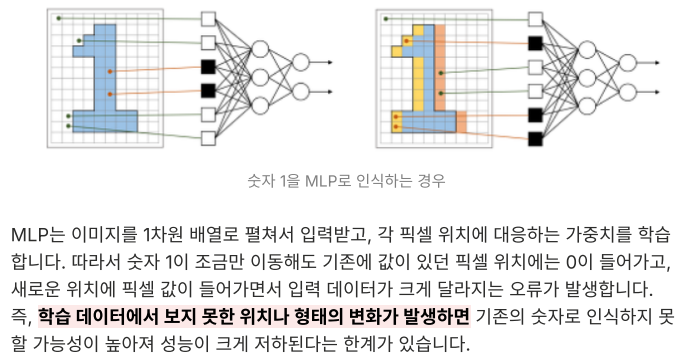

- MLP 는 위치, 크기 회전 등의 변화에 취약함
- CNN 은 conv 통해서 이미지 특징 추출, 탐지 가능
- pool은 작은 위치 변화에도 비슷한 특징 유지하도록 도움

### 파라미터 폭발

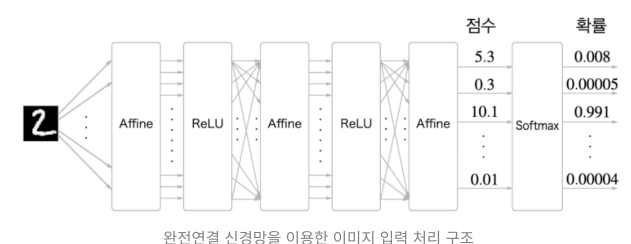

- MLP는 완전연결 구조라서 파라미터 급증 일어남, 가중치 개수 - 이미지 픽셀 개수만큼 생성됨

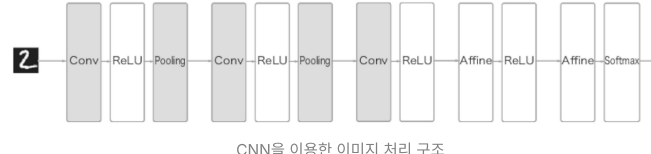

- 반면 CNN
- 이미지 크기가 커지더라도 필터의 크기와 개수가 동일하다면 파라미터 수는 크게 증가하지 X

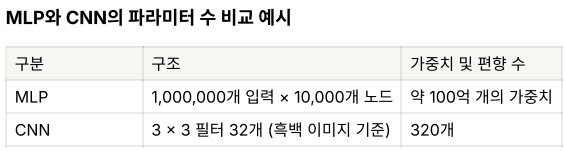

- mlp는 2/3차원 이미지 데이터를 1차원으로 펼치는 flatten함(퉁퉁사후르)

- 픽셀 간의 위치 관계나 주변 픽셀들이 모여 만들어내는 특징을 직접적으로 활용하기 어렵다는 한계

- CNN
- 이미지의 공간적 특징을 먼저 학습한 후 Flatten을 수행
- 픽셀의 위치 관계와 주변 영역의 특징을 활용하는 데 유리






#  CONV & POOL

### conv layer
- 입력 이미지 전체를 일정한 크기의 필터로 훑으면서 이미지의 특징을 추출하고 학습하는 계층
- 필터: 수직선, 수평선, 모서리, 질감 등과 같은 이미지의 특정한 패턴이나 특징을 감지하는 역할

- 커널 (Kernel)
   - 이미지의 특정 패턴(선, 모서리 등)을 추출하기 위해 사용하는 2차원 가중치 행렬
- 필터 (Filter)
    - 여러 개의 커널(Kernel)이 모인 집합(묶음)

커널이 각 채널(이미지 색상정보 저장된 데이터층)을 연산한 뒤 결과를 하나의 채널(피처맵) 만들어냄

피처맵: conv 연산을 통해 생성되는 결과 d
필터가 특정 특징에 반응할수록, 해당 위치의 피처맵 값이 커짐

- CNN은 여러 개의 필터를 사용하여 이미지의 다양한 특징을 추출 
- ex) 가로선 감지 필터, 세로선 감지 필터

### 패딩
- Padding은 Convolution 연산을 수행하기 전에 입력 이미지의 가장자리에 추가적인 픽셀을 삽입하는 방법

- 왜씀?: Convolution 연산으로 인해 이미지의 크기가 지나치게 작아지는 것을 방지
- 1) 공간적 크기를 유지
- 2) 가장자리의 특징까지 학습

### 스트라이드(보폭)

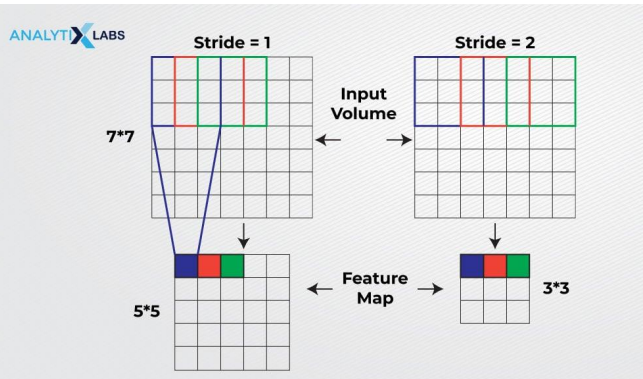

- stride1 =세부적인 특징을 추출하는 데 유리
- stride2= 산량을 줄이고 Feature Map의 크기를 축소

### 풀링

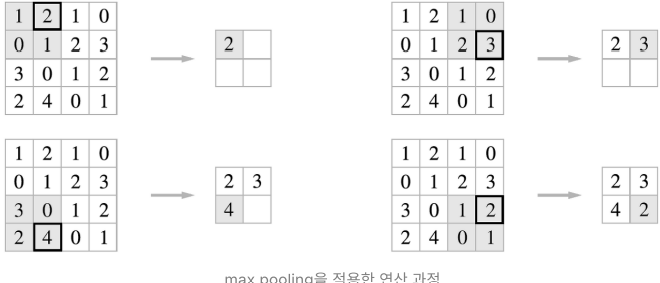
- 크기 영역 설정 & 해당 영역에 포함된 값들을 하나의 값으로 요약
- 일반적으로 2 곱하기 2
- 각 영역에서 min혹은 max 사용

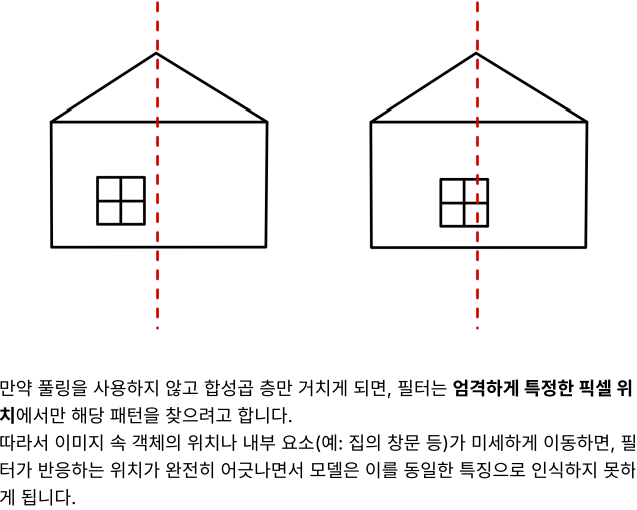

- 맥스 풀링:최댓값 사용
- 애버리지풀링: 지정영역 안의 모든 값의 평균을 사용

- 장점: ㄱ계산량 감소, 위치 변화에 강함, 과적합 방지, 노이즈 완화


# CNN 전체 구조

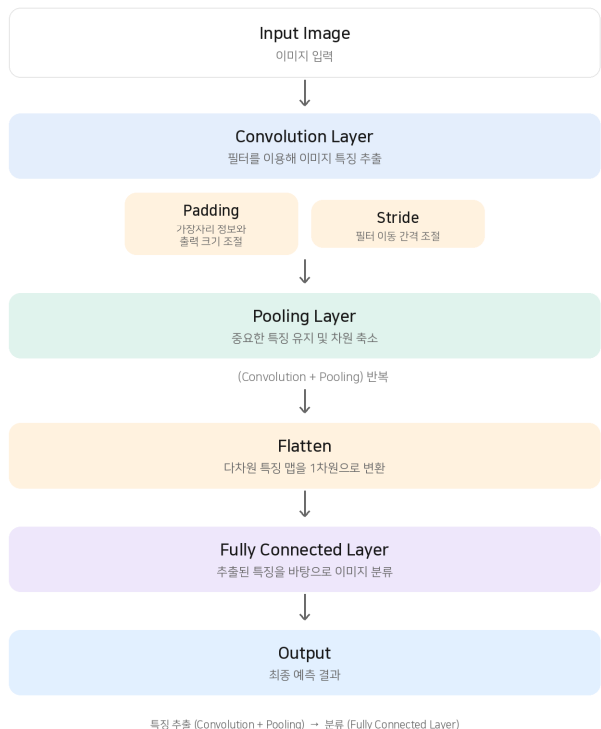










### 이미지 딥러닝 응용
- 이미지 분류 모델

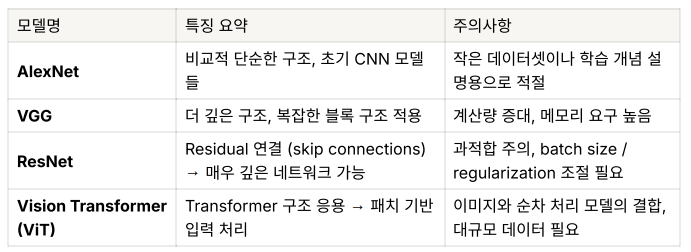

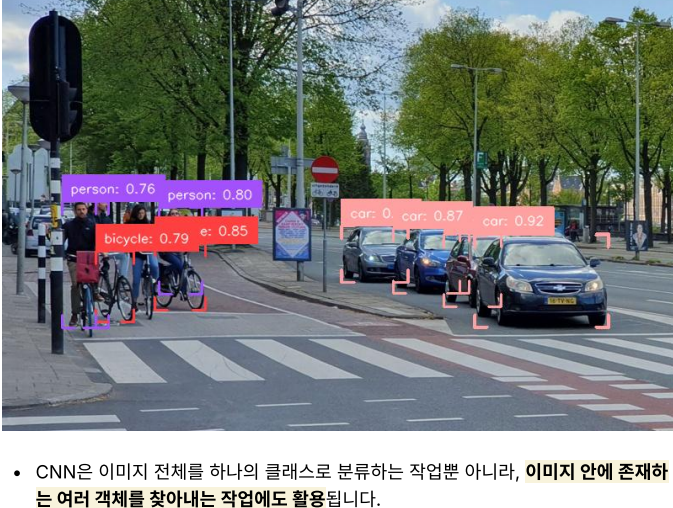

- bounding box: 이미지에서 객체가 위치한 영역을 둘러싸는 사각형

### 이미지 캡셔닝

- 이미지의 내용을 자연어 문장으로 표현하는 작업

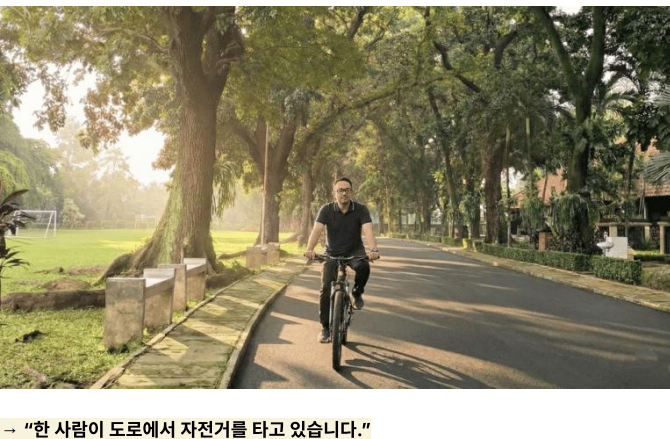

이미지와 글을 같이 사용하기 때문에 cnn과 rnn이 함께 사용됨



# RNN
### 순차 데이터 (시퀀스 데이터)

순차 d: 데이터의 순서가 의미를 갖는 데이터로, 순서를 바꾸면 정보가 달라지는 데이터

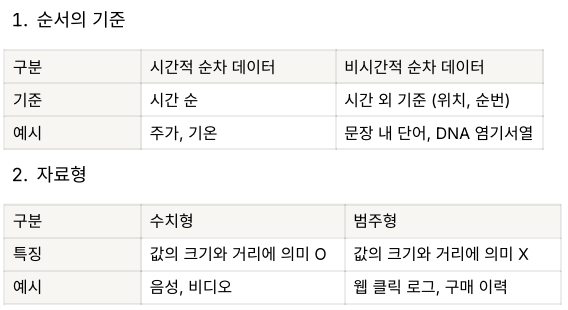

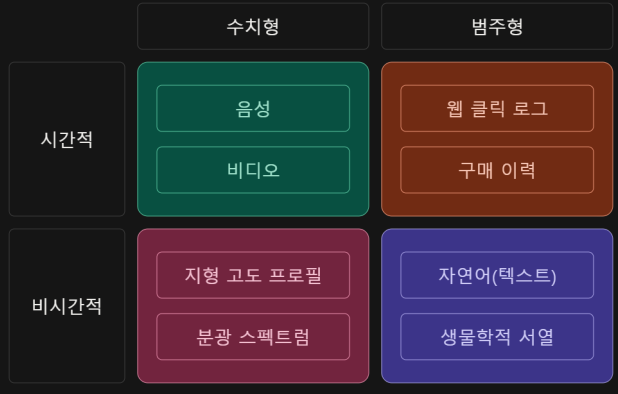


- 정형 데이터 : 고객 A, B, C 행 순서를 C, A, B로 바꿔도 → 의미 변화 X
- 순차 데이터 : "개가 사람을 물었다" → "사람이 개를 물었다" → 완전히 다른 의미

순차 데이터 처리해야 해서 RNN이 필요하다

- 핵심 : 매 시점마다 현재 시점 입력값과 이전 시점 은닉상태를 이용해 현재의 은닉상태를 계산하고 그 결과를 다음 시점으로 넘겨줌


### 아키텍처 
- one to many

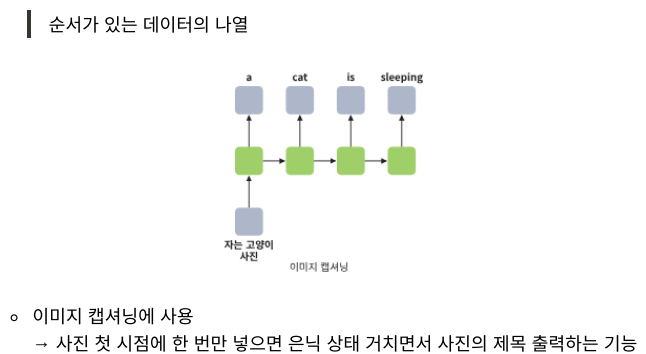

- many to one

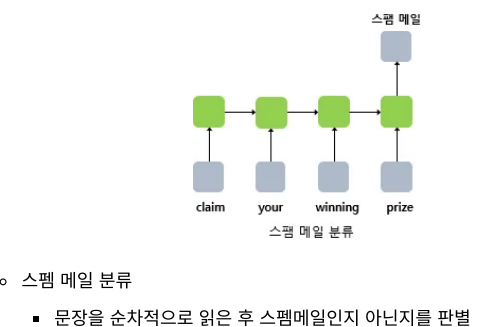

- many to many

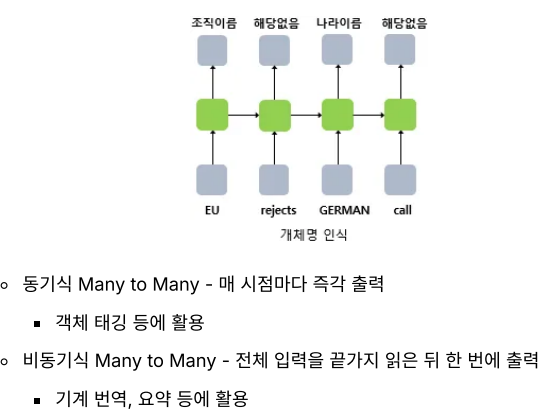


### RNN의 한계점

- 시간에 따른 역전파(Back Propagation Through Time) 구조

 - RNN은 순전파를 통해 시퀀스를 처리한 뒤, 시간을 거슬러 올라가며(BPTT) 오차를 전파하여 가중치 기울기를 누적 계산


- 기울기 소실 (Vanishing Gradients)
- 역전파 과정에서 기울기가 과거 시점으로 갈수록 점점 작아져 0에 가까워지는 현상

- 느린 훈련 시간
- RNN은 시점을 하나씩 순서대로만 계산할 수 있어서, 시퀀스가 길수록 학습에 시간이
오래 걸리게 됨

- 장기 의존성 문제 (Long-Term Dependency Problem)
- 시퀀스에서 관련된 정보가 멀리 떨어져 있을수록, RNN이 그 관계를 기억하고 학습하지 못하는 문제


# 똑똑하게 기억하고 잊는 법: LSTM & GRU
- LSTM (Long Short-Term Memory) : 기억을 두 개의 상태로 나눠서 관리

1. Forget Gate
→ 장기 기억에서 더 이상 필요 없는 내용을 삭제
2. Input Gate
→ 새로 들어온 정보 중 중요한 것만 장기기억에 저장
3. Output Gate
→ 장기기억 중 지금 필요한 부분만 꺼내 단기기억으로 내보냄

- 장기 기억과 단기 기억을 분리해서 관리 → 정보를 정교하게 다룰 수 있음
- 대신 게이트 3개 + 상태 2개 → 구조가 복잡하고 계산량이 많음

- GRU (Gated Recurrent Unit) : 기억을 하나로 통합해서 관리
- 셀 상태와 은닉 상태로 나누지 않고, 은닉 상태 하나에 기억과 출력을 모두 포함

- 게이트 2개 + 상태 1개 → LSTM보다 단순하고 계산이 빠름
- 대신 기억을 세밀하게 나누지 않아 정교함은 상대적으로 떨어짐


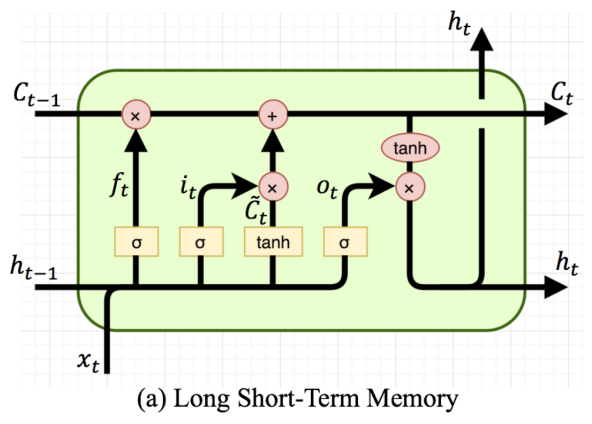
- 게이트가 정보를 빼거나(잊기) 더해서(기억하기) 조절

- 게이트에는 forget gate, input gate, output gate가 있음

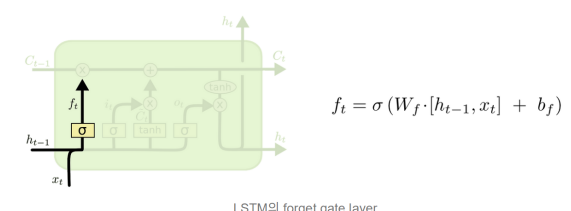

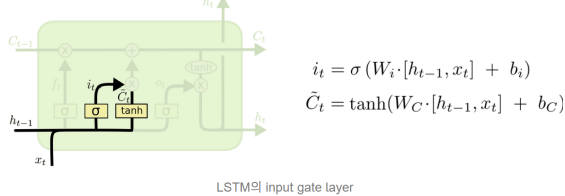

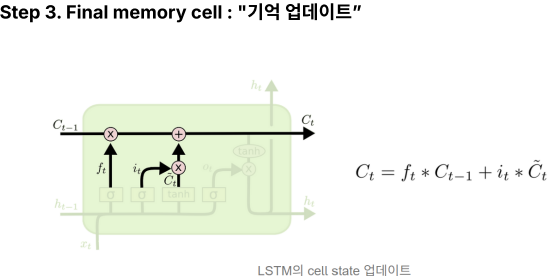

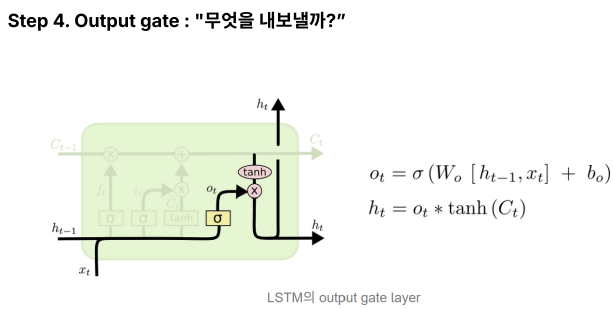

### GRU 
- GRU = LSTM의 핵심 아이디어(게이트로 정보를 선택적으로 기억·삭제)는 유지하면서,
구조를 단순하게 줄인 모델

- 특징
    - 1. Forget gate와 Input gate를 Update gate 하나로 통합
    - 2. Reset gate를 사용
    - 3. Output gate가 없음
    - 4. Gate의 개수가 3개에서 2개로 감소

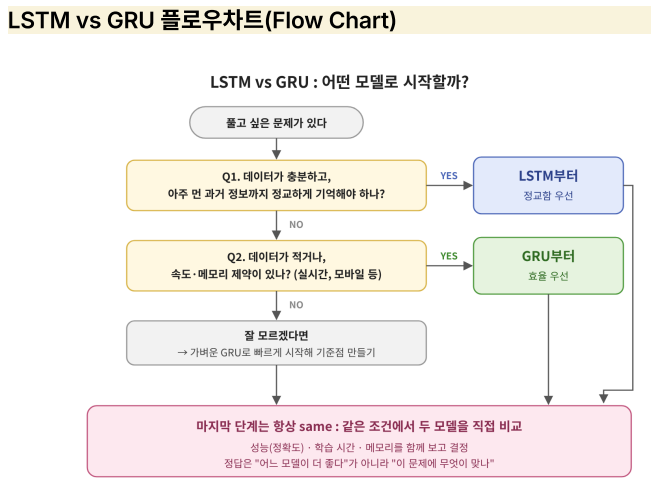

# 문장을 입력받아 문장을 출력하다: Seq2Seq

### Seq2Seq의 기본 구조
- 인코더와 디코더

- Sequence-to-Sequence : 입력 시퀀스를 받아 다른 시퀀스를 출력하는 모델
- 입력과 출력의 길이가 서로 달라도 됨 → 기존 RNN과의 가장 큰 차이 

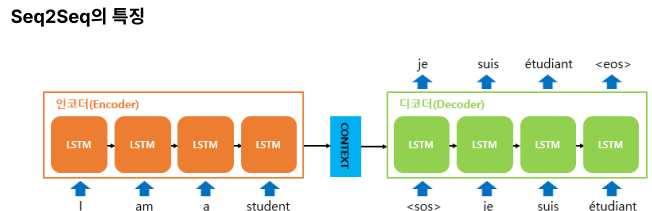

- 읽고 (인코더) → 요약해서 넘기고 (컨텍스트 벡터) → 다시 써낸다 (디코더)

### 인코더

- ① 단어 토큰화 : 입력 문장을 단어 단위로 나눔 → "I", "am", "a", "student"
- ② 임베딩(embedding) : 각 단어를 컴퓨터가 계산할 수 있는 숫자 벡터로 변환
- ③ LSTM 셀에 한 단어씩 입력 : 매 시점 은닉 상태가 다음 시점으로 전달되며 정보가 누적
됨
- ④ 마지막 시점의 은닉 상태 = 문장 전체 정보가 담긴 컨텍스트 벡터
    → 디코더로 전달

### 디코더

- ① 컨텍스트 벡터를 디코더 LSTM의 첫 은닉 상태로 받음
- ② 시작 신호 <sos>(start of sequence)를 첫 입력으로 넣음
- ③ 매 시점 softmax로 다음 단어의 확률을 계산 → 가장 확률이 높은 단어 선택(argmax)
- ④ 방금 예측한 단어를 다음 시점의 입력으로 다시 넣음
    - ex) <sos> → "je" → "suis" → "étudiant" (그림의 분홍 점선 화살표)
- ⑤ 종료 신호 <eos>(end of sequence)가 나오면 생성 종료

### 콘텍스트 벡터
- 인코더가 입력 문장 전체를 읽고 만든 문장 요약 벡터

- Seq2Seq의 한계: 병목 현상 (Bottleneck)
- 인코더가 입력 문장 전체를 ‘고정된 크기의 컨텍스트 벡터 하나’에 압축하면서 정보가 좁은 통로에 막혀 손실되는 현상

- 긴 문장일수록 정보를 다 담지 못하고 손실되는 정보 발생
- 앞 단어는 여러 시점을 거치며 희미해지므로, 장기 의존성 문제 여전히 존재






